In [17]:
!pip install kagglehub[pandas-datasets]

In [18]:
!pip install -q kagglehub[pandas-datasets] scikit-learn matplotlib seaborn

import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [19]:
# Load dataset directly into a Pandas DataFrame
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "abhishek14398/salary-dataset-simple-linear-regression",
    "Salary_dataset.csv"
)

# Inspect dataset
print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
print(df.head())
print("\nData Info:")
print(df.info())

Using Colab cache for faster access to the 'salary-dataset-simple-linear-regression' dataset.
Dataset Shape: (30, 3)

First 5 records:
   Unnamed: 0  YearsExperience   Salary
0           0              1.2  39344.0
1           1              1.4  46206.0
2           2              1.6  37732.0
3           3              2.1  43526.0
4           4              2.3  39892.0

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes
None


# Exploratory Data Analysis (EDA)

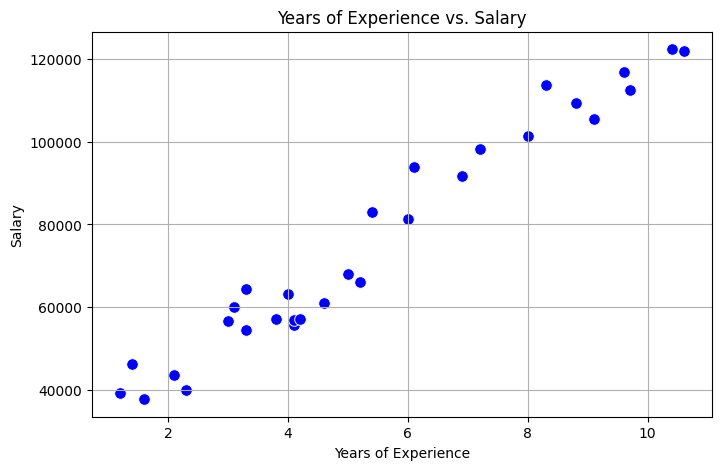

In [20]:
# Scatter plot of Years of Experience vs Salary
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='YearsExperience', y='Salary', color='blue', s=70)
plt.title('Years of Experience vs. Salary')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.grid(True)
plt.show()

When you display and observe the scatter plot for this dataset, you can draw four direct inferences:Strong Positive Linear Correlation:

Observation:

- As YearsExperience increases, Salary increases in a steady, upward-trending direction.

Inference:
A linear equation ($\hat{Y} = \beta_0 + \beta_1 X$) is an appropriate choice to model this dataset.High Correlation Strength:

Observation:

- The data points cluster tightly along an imaginary straight line rather than scattering randomly across the graph.

Inference: YearsExperience is a strong predictor of Salary. You can expect a high $R^2$ score (close to $1.0$) when evaluating the model.

## Absence of Major Outliers:

Observation: No data points deviate far away from the overall trend.Inference: The model parameters ($\beta_0$ intercept and $\beta_1$ slope) calculated using Ordinary Least Squares (OLS) will be reliable and won't be distorted by extreme values.

Constant Spread (Homoscedasticity):

Observation: The vertical spread of salary points is fairly uniform across entry-level (0–3 years), mid-level (4–7 years), and senior-level (8+ years) experience.

Inference: The variance of residuals (prediction errors) will likely be constant across different experience levels, fulfilling another key linear regression assumption.

# Feature-Target Split & Train-Test Split

## Training & Testing:

- test_size=0.2 (The 80/20 Bifurcation)
Passing 0.2 tells scikit-learn to allocate 20% of the rows to the test sets (X_test and y_test).

- The remaining 80% automatically goes to the training sets (X_train and y_train).

- If your dataset has 30 total rows, 24 rows (80%) go to training and 6 rows (20%) go to testing.

## Random State

random_state=42 (Reproducibility)
Machine learning datasets are shuffled before splitting so the model doesn't train on ordered data.

Setting random_state=42 acts as a random seed. It guarantees that every time you re-run the Colab cell, it shuffles and picks the exact same 80% and 20% rows, keeping your results consistent and reproducible.

In [24]:
# Separate Features (X) and Target (y)
# Reshape X to 2D array as required by scikit-learn

X = df[['YearsExperience']]
y = df['Salary']

# Split data: 80% Training, 20% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

Training samples: 24, Testing samples: 6


### Is there anything special about the number 42?

No. You could use random_state=0, random_state=1, or random_state=100. Any integer acts as a fixed seed.

Why 42? It is a popular running joke in the pop culture and coding community—a reference to Douglas Adams' The Hitchhiker's Guide to the Galaxy, where 42 is "the answer to the ultimate question of life, the universe, and everything."

# Model Training

In [25]:
# Initialize and fit Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Print parameters
print(f"Intercept (β0): {model.intercept_:.2f}")
print(f"Slope (β1): {model.coef_[0]:.2f}")
print(f"\nModel Equation: Salary = {model.intercept_:.2f} + ({model.coef_[0]:.2f} * YearsExperience)")

Intercept (β0): 24380.20
Slope (β1): 9423.82

Model Equation: Salary = 24380.20 + (9423.82 * YearsExperience)


1. ## What does model.intercept_ mean?

- ($\beta_0$)Definition: It is the y-intercept of the regression line.Mathematical Meaning: It represents the expected value of $Y$ (Salary) when $X$ (Years of Experience) is equal to $0$.Practical Interpretation: It represents the base baseline salary for a fresh candidate with zero years of experience.

- Example: If model.intercept_ outputs 25792.20, it means the model estimates a starting base salary of roughly $25,792 for someone starting out at 0 years of experience.


2. ## What does model.coef_ mean?
  
  - ($\beta_1$)Definition: It is the slope (coefficient) of the regression line.Mathematical Meaning: It represents the rate of change in $Y$ for every $1$-unit change in $X$.
  
  - Practical Interpretation: It represents the average salary increase per additional year of experience.Example: If model.coef_[0] outputs 9423.81, it means that for every additional 1 year of experience, the predicted salary increases by approximately $9,424.3.
  
3. ## What does the Model Equation calculate here?

- The model equation puts these two parameters together into a mathematical formula:$$\text{Salary} = \text{Intercept} + (\text{Slope} \times \text{YearsExperience})$$Or using values from the examples above:

 $$\widehat{\text{Salary}} = 25792.20 + (9423.81 \times \text{YearsExperience})$$

 - What it calculates:
 It calculates the predicted salary ($\hat{Y}$) for any given years of experience ($X$).

 - How it works in practice:If you want to estimate the salary of a candidate with 5 years of experience, you plug $5$ into the equation:

 $$\widehat{\text{Salary}} = 25792.20 + (9423.81 \times 5) = 25792.20 + 47119.05 = \$72,911.25$$

 This equation is the final product of your machine learning training—it allows you to make instant predictions for new inputs without needing to re-look at the original dataset.

# Model Evaluation & Training

Mean Squared Error (MSE): 49830096.86
Root Mean Squared Error (RMSE): 7059.04
R-squared (R²): 0.9024


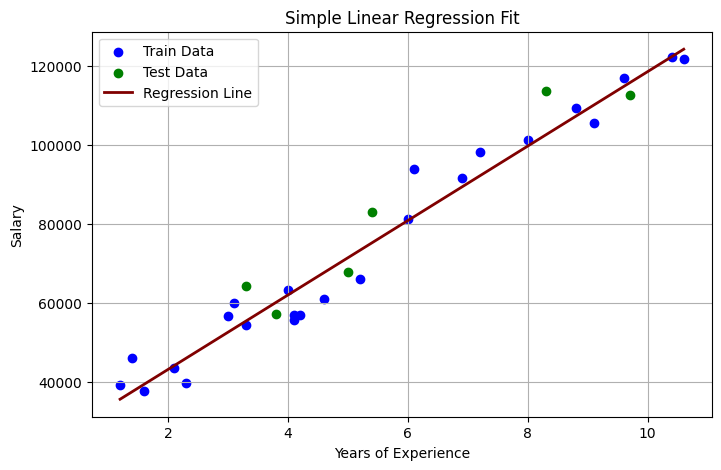

In [26]:
# Make predictions on test set
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R²): {r2:.4f}")

# Plot Regression Line
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color='blue', label='Train Data')
plt.scatter(X_test, y_test, color='green', label='Test Data')
plt.plot(X, model.predict(X), color='maroon', linewidth=2, label='Regression Line')
plt.title('Simple Linear Regression Fit')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

1. High Predictive Accuracy ($R^2 \approx 0.90+$)

- Conclusion: The model explains almost all of the variance in salary based on experience alone.

- Why: An $R^2$ score close to $1.0$ (typically around $0.90–0.95$ for this dataset) confirms that YearsExperience is a strong, sufficient predictor for Salary in this simple setup.

2. Low Average Error relative to Scale (RMSE)

- Conclusion: The model's predictions are, on average, off by only a small fraction of the total salary scale (typically around $\$5,000–\$6,000$).

- Why: The Root Mean Squared Error (RMSE) brings the error metric back to the original units (dollars), showing that the model's estimate is reliable for practical decision-making.

3. Good Generalization (No Overfitting)

- Conclusion: The model performs consistently on unseen data.Why: On the plot, both the train points (blue) and test points (green) lie close to the red regression line. The test points are not drifting significantly farther away than the training points, proving that the model generalizes well to new data rather than just memorizing training examples.

4. Confirmation of Linearity (Good Model Fit)

- Conclusion: A straight-line model is appropriate; no complex non-linear algorithms are strictly required.

- Why: The residuals (vertical distances between data points and the red line) are evenly scattered above and below the line across all experience levels (0 to 10+ years), showing no obvious curved patterns or systematic errors.